# Exercise 2 · EDA — Passau MedCo workforce & attrition

**Question:** What does our workforce look like, and which patterns show up in the data?

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
BLUE, RED = "#4c72b0", "#c44e52"

raw = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
raw.shape

(1470, 35)

## 1 Data check & preparation

In [3]:
constant = [c for c in raw if raw[c].nunique() == 1]
ids = [c for c in raw if raw[c].nunique() == len(raw)]
print(f"missing values: {raw.isna().sum().sum()} | duplicate rows: {raw.duplicated().sum()}")
print(f"constant columns: {constant} | ID columns: {ids}")

missing values: 0 | duplicate rows: 0
constant columns: ['EmployeeCount', 'Over18', 'StandardHours'] | ID columns: ['EmployeeNumber']


No missing values and no duplicate rows, so nothing to repair.
Three columns have the same value for everyone and one is just an ID. They carry no information, so we drop them.
The target becomes `Left` (1 = employee left).

In [4]:
df = raw.drop(columns=constant + ids)
df["Left"] = (df.pop("Attrition") == "Yes").astype(int)
base = df["Left"].mean()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = df.select_dtypes("number").columns.drop("Left").tolist()
print(f"{df.shape[0]} employees, {df.shape[1] - 1} features ({len(cat_cols)} categorical, {len(num_cols)} numeric)")
print(f"attrition: {df['Left'].sum()} of {len(df)} = {base:.1%}")

1470 employees, 30 features (7 categorical, 23 numeric)
attrition: 237 of 1470 = 16.1%


**Few leavers:** only about 16 % left. A model that says "everyone stays" would be right 84 % of the time, so accuracy alone tells us little later on.

## 2 Workforce profile

In [5]:
df[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "DistanceFromHome"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.9,9.1,18.0,30.0,36.0,43.0,60.0
MonthlyIncome,1470.0,6502.9,4708.0,1009.0,2911.0,4919.0,8379.0,19999.0
TotalWorkingYears,1470.0,11.3,7.8,0.0,6.0,10.0,15.0,40.0
YearsAtCompany,1470.0,7.0,6.1,0.0,3.0,5.0,9.0,40.0
YearsInCurrentRole,1470.0,4.2,3.6,0.0,2.0,3.0,7.0,18.0
DistanceFromHome,1470.0,9.2,8.1,1.0,2.0,7.0,14.0,29.0


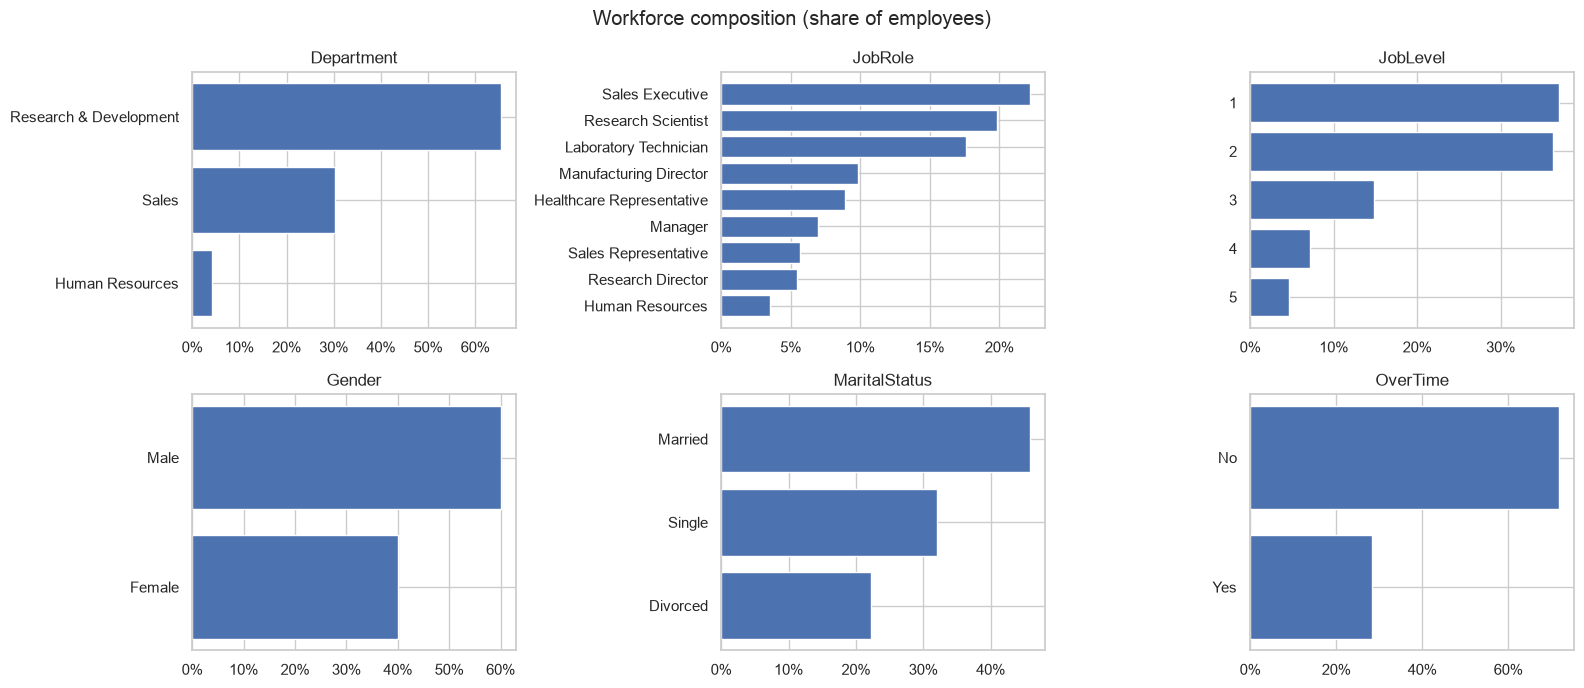

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.flat, ["Department", "JobRole", "JobLevel", "Gender", "MaritalStatus", "OverTime"]):
    s = df[c].value_counts(normalize=True).sort_values()
    ax.barh(s.index.astype(str), s, color=BLUE)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(c)
fig.suptitle("Workforce composition (share of employees)")
fig.tight_layout()

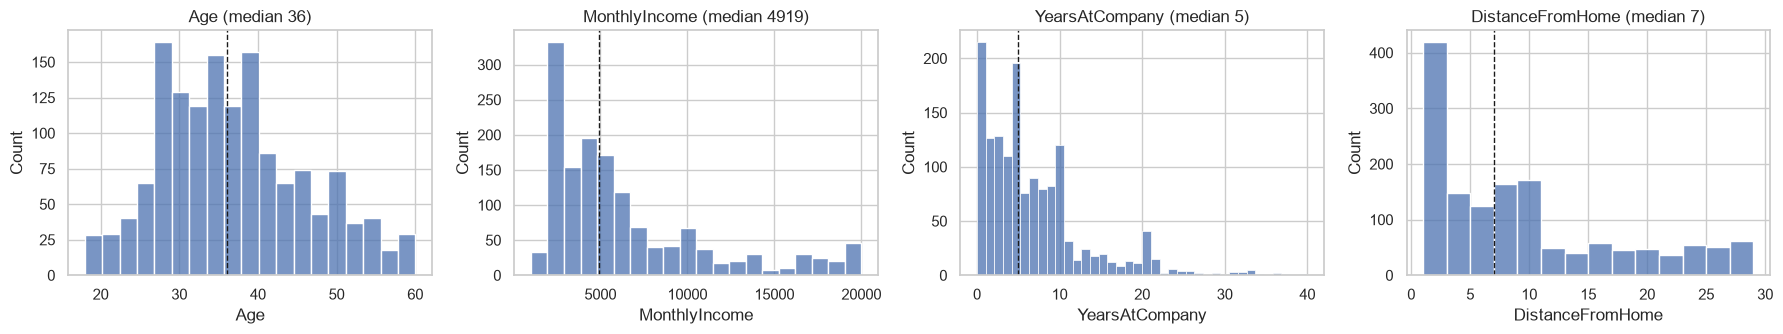

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, c in zip(axes, ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]):
    sns.histplot(df[c], ax=ax, color=BLUE)
    ax.axvline(df[c].median(), ls="--", c="k", lw=1)
    ax.set_title(f"{c} (median {df[c].median():g})")
fig.tight_layout()

## 3 Attrition patterns
Each bar shows the share of a group that left.
- Dashed line = company average (16 %).
- **Red** = above average, **blue** = at or below average.
- `n` = number of employees in the group.

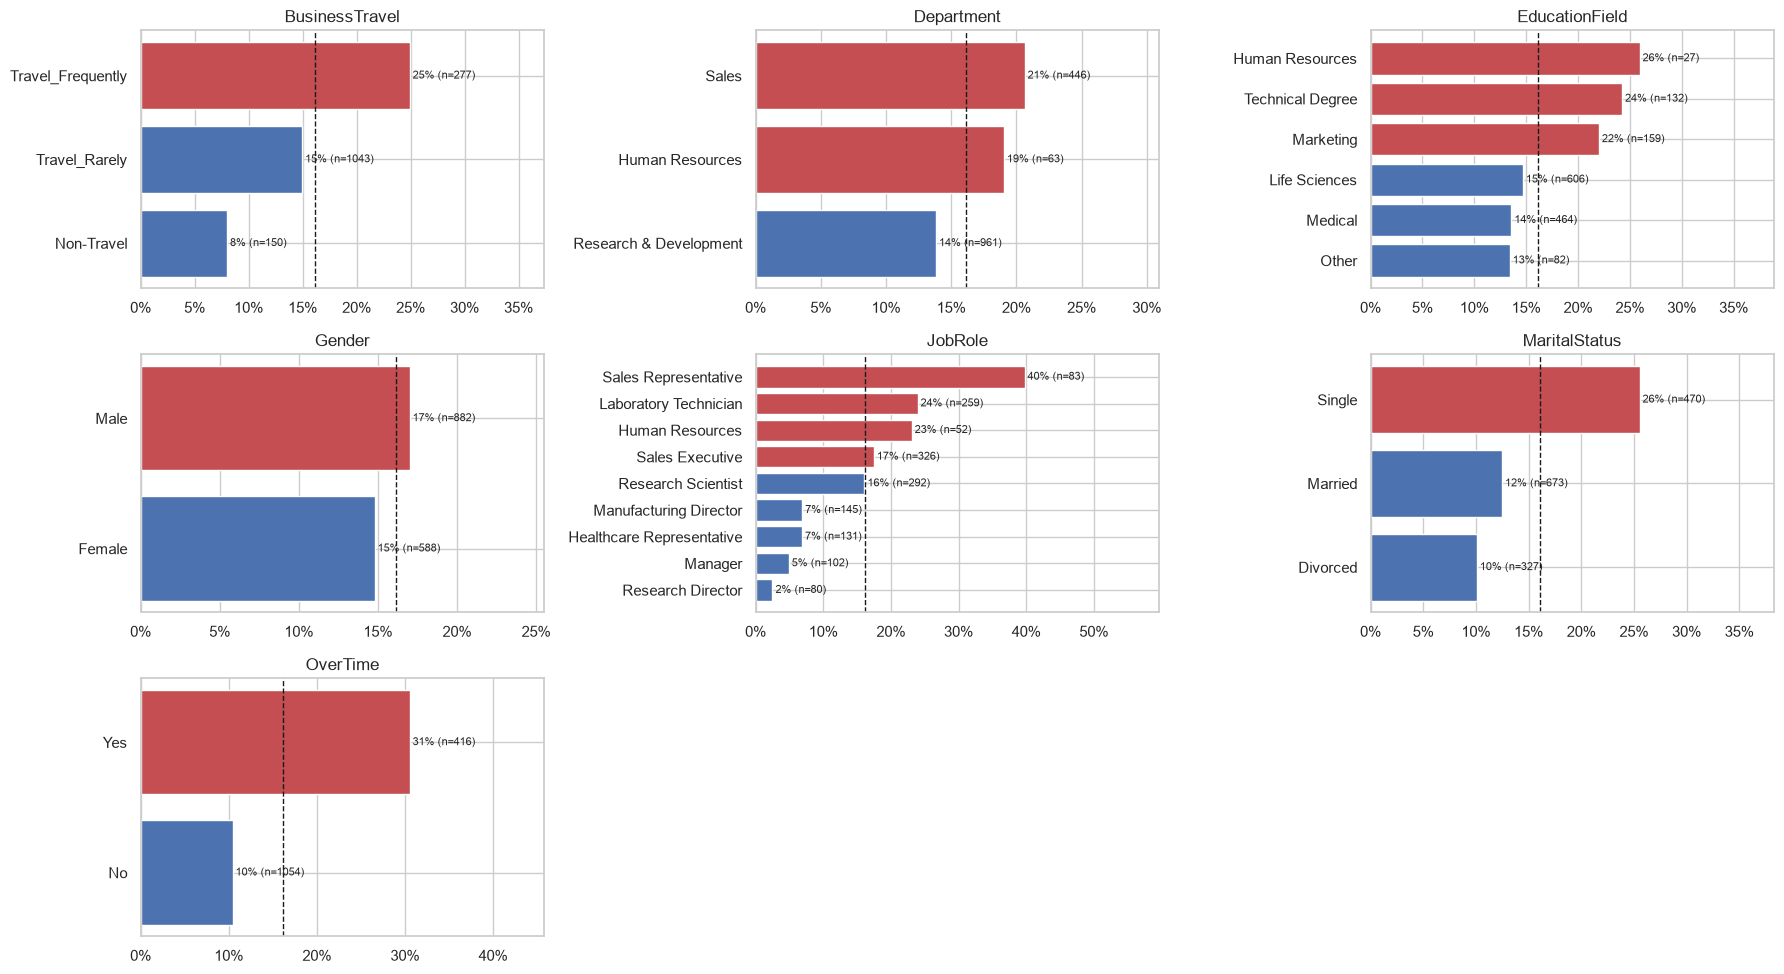

In [6]:
def rate_plots(cols, sort=True, ncols=3):
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.3 * nrows), squeeze=False)
    for ax, c in zip(axes.flat, cols):
        g = df.groupby(c)["Left"].agg(["mean", "size"])
        g = g.sort_values("mean") if sort else g.sort_index(ascending=False)
        ax.barh(g.index.astype(str), g["mean"], color=[RED if m > base else BLUE for m in g["mean"]])
        ax.axvline(base, ls="--", c="k", lw=1)
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(m, i, f" {m:.0%} (n={n})", va="center", fontsize=8)
        ax.set_xlim(0, g["mean"].max() * 1.5)
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.set_title(c)
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    fig.tight_layout()


rate_plots(cat_cols)

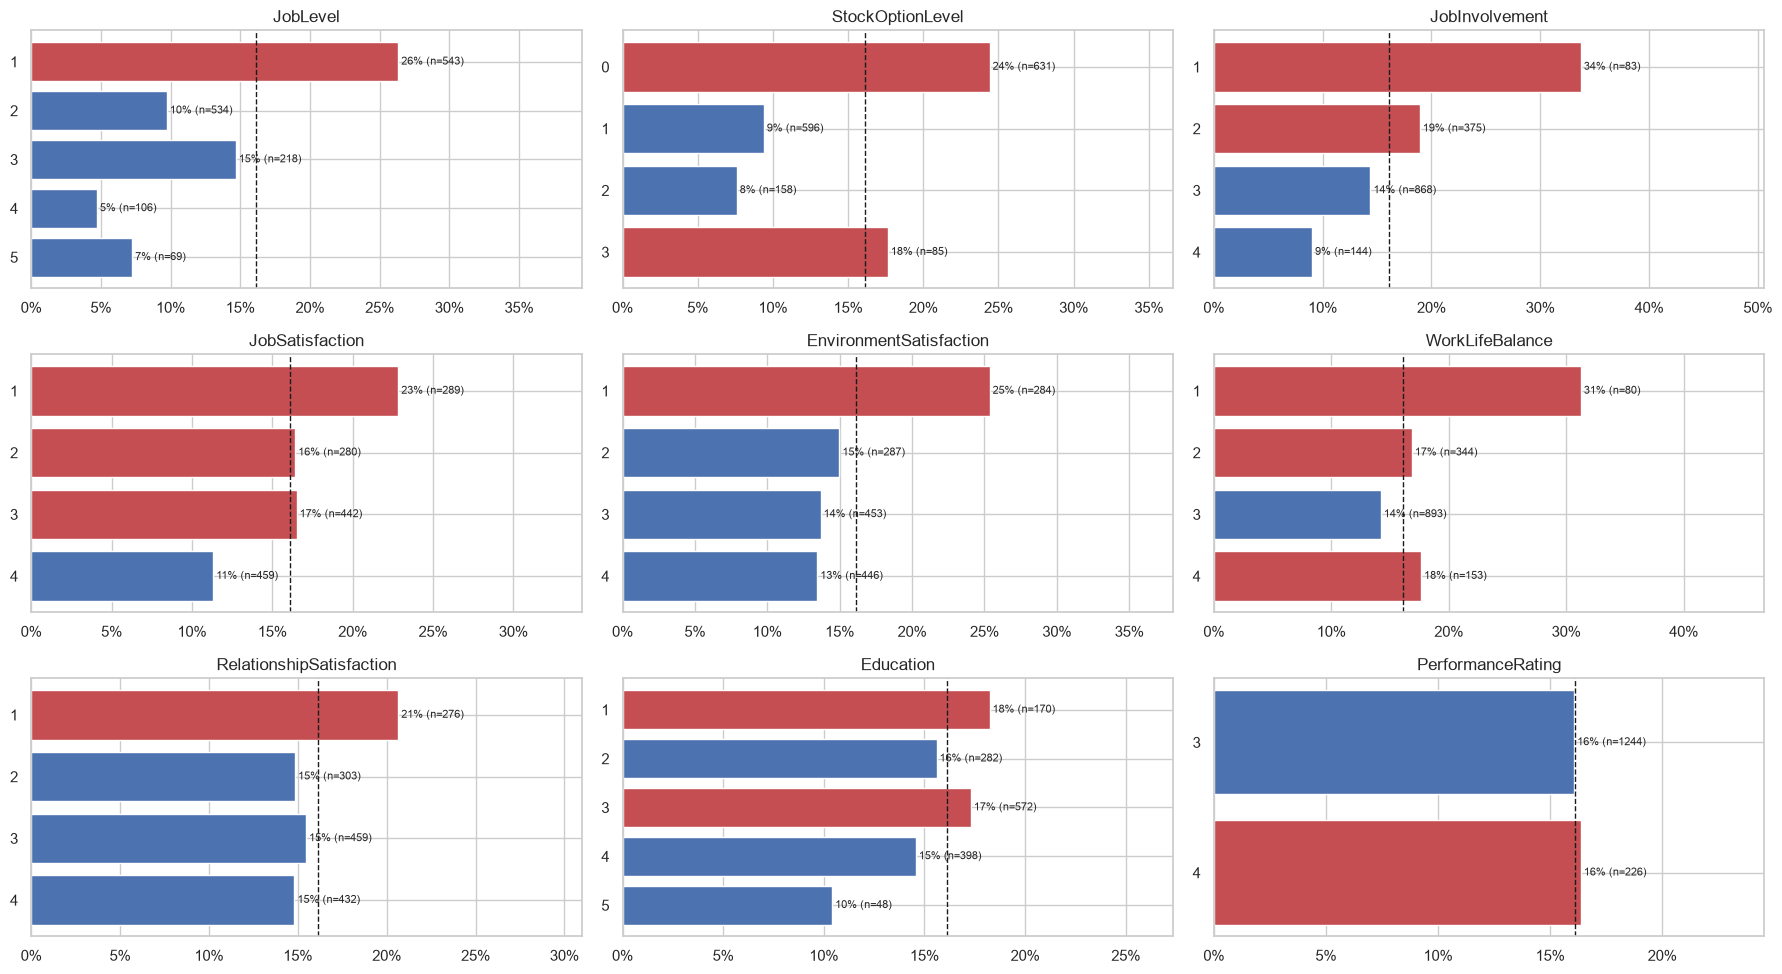

In [8]:
ordinal = ["JobLevel", "StockOptionLevel", "JobInvolvement", "JobSatisfaction", "EnvironmentSatisfaction",
           "WorkLifeBalance", "RelationshipSatisfaction", "Education", "PerformanceRating"]
rate_plots(ordinal, sort=False)

**Reading the box plots.** Blue = stayed, red = left. The line in each box is the typical value (median). The box holds the middle half of the employees.

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsWithCurrManager,DistanceFromHome,NumCompaniesWorked
Left,,,,,,,,
Stayed,36.0,5204.0,10.0,6.0,3.0,3.0,7.0,2.0
Left,32.0,3202.0,7.0,3.0,2.0,2.0,9.0,1.0


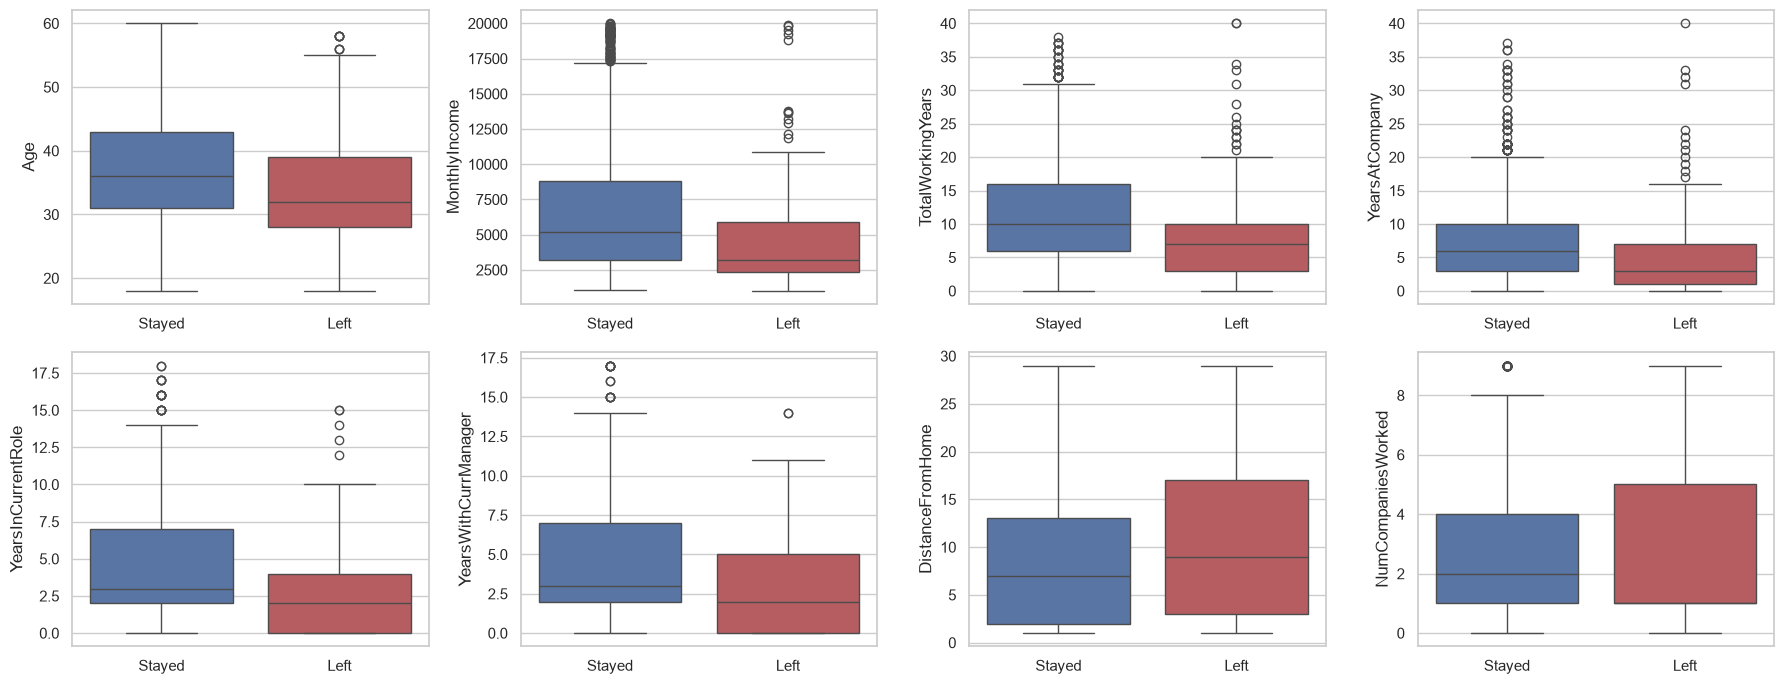

In [9]:
cont = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
        "YearsWithCurrManager", "DistanceFromHome", "NumCompaniesWorked"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, cont):
    sns.boxplot(data=df, x="Left", y=c, hue="Left", palette=[BLUE, RED], legend=False, ax=ax)
    ax.set_xticks([0, 1], ["Stayed", "Left"])
    ax.set_xlabel("")
fig.tight_layout()
df.groupby("Left")[cont].median().rename(index={0: "Stayed", 1: "Left"})

Leaving is most common among young, new and low-paid employees:

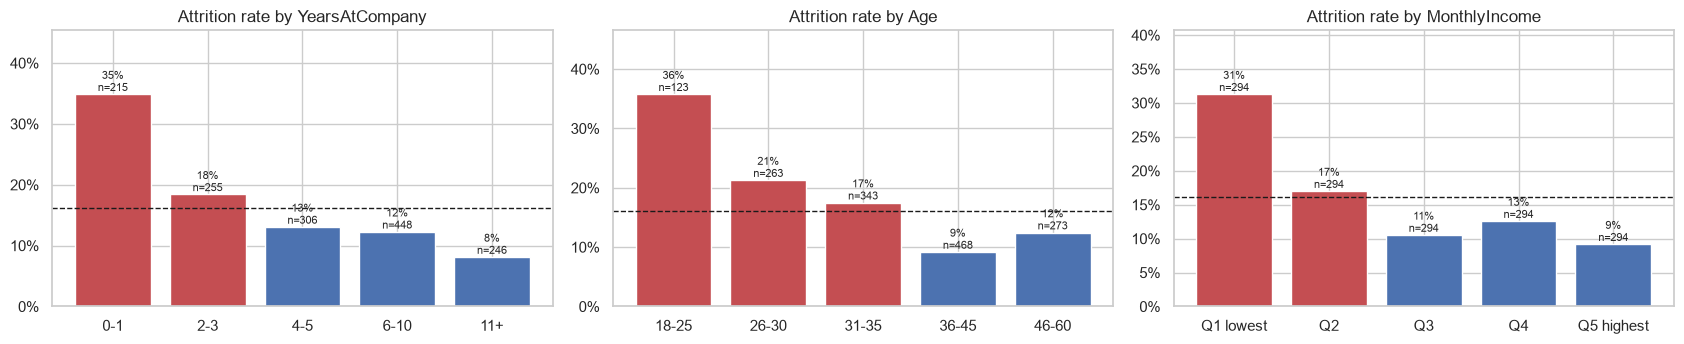

In [10]:
bands = {
    "YearsAtCompany": pd.cut(df["YearsAtCompany"], [-1, 1, 3, 5, 10, 40], labels=["0-1", "2-3", "4-5", "6-10", "11+"]),
    "Age": pd.cut(df["Age"], [17, 25, 30, 35, 45, 60], labels=["18-25", "26-30", "31-35", "36-45", "46-60"]),
    "MonthlyIncome": pd.qcut(df["MonthlyIncome"], 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]),
}
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, (c, b) in zip(axes, bands.items()):
    g = df.groupby(b, observed=True)["Left"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=[RED if m > base else BLUE for m in g["mean"]])
    ax.axhline(base, ls="--", c="k", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m, f"{m:.0%}\nn={n}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, g["mean"].max() * 1.3)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(f"Attrition rate by {c}")
fig.tight_layout()

## 4 How features relate

JobLevel            MonthlyIncome           0.95
                    TotalWorkingYears       0.78
PercentSalaryHike   PerformanceRating       0.77
MonthlyIncome       TotalWorkingYears       0.77
YearsAtCompany      YearsWithCurrManager    0.77
                    YearsInCurrentRole      0.76
YearsInCurrentRole  YearsWithCurrManager    0.71
dtype: float64

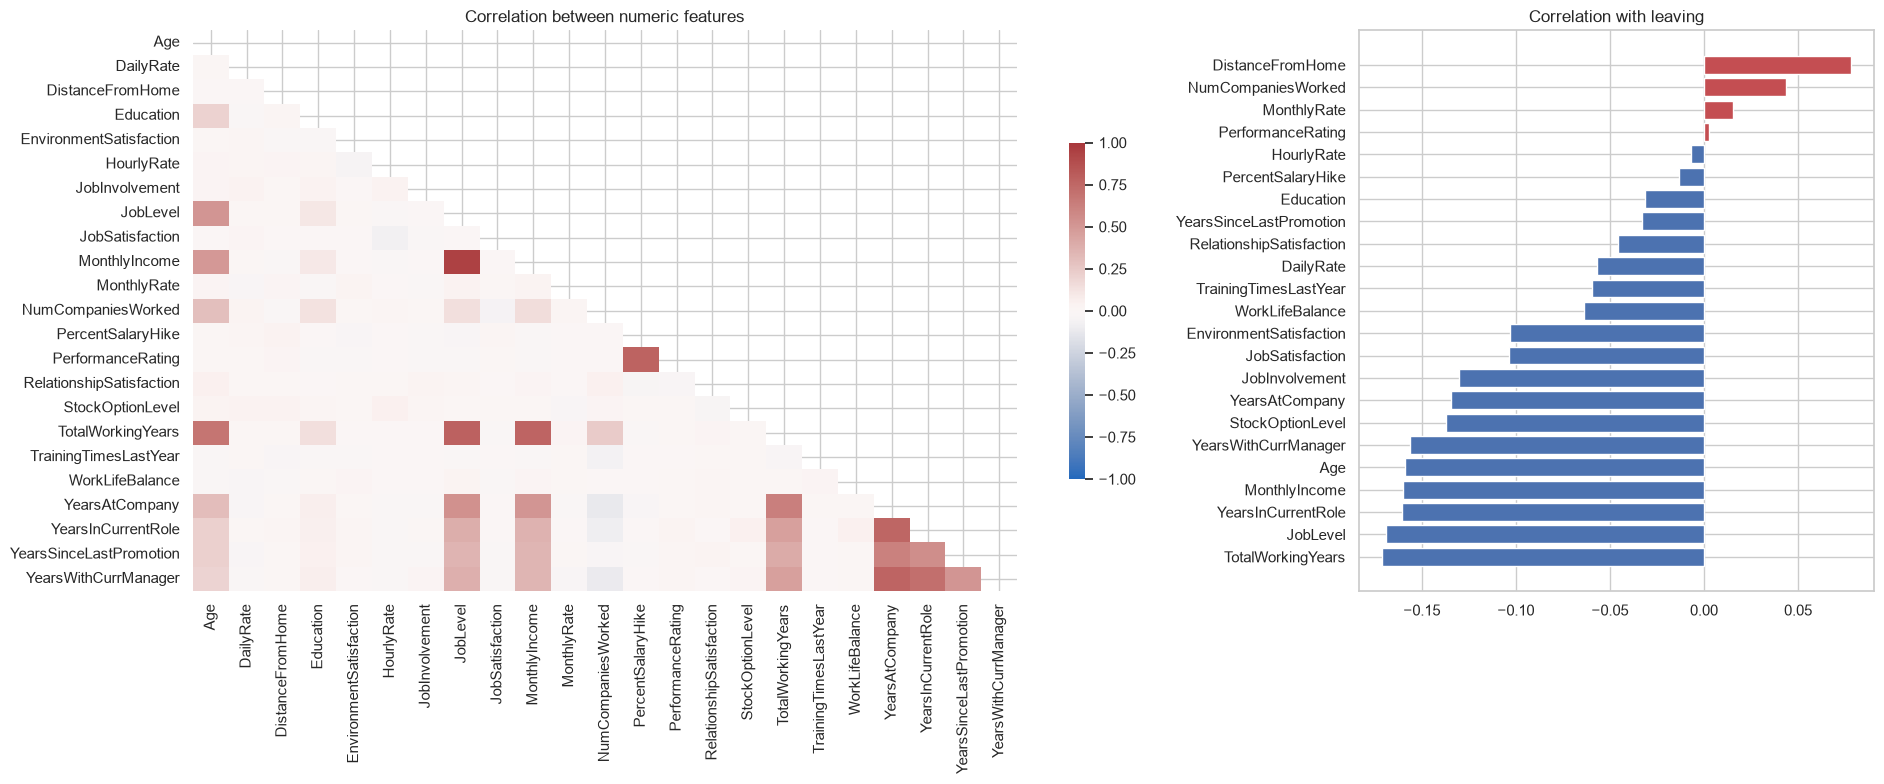

In [11]:
corr = df[num_cols + ["Left"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(19, 8), width_ratios=[2, 1])
sns.heatmap(corr.drop(index="Left", columns="Left"), cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0],
            mask=np.triu(np.ones((len(num_cols),) * 2, bool)), cbar_kws={"shrink": 0.6})
axes[0].set_title("Correlation between numeric features")
t = corr["Left"].drop("Left").sort_values()
axes[1].barh(t.index, t, color=[RED if v > 0 else BLUE for v in t])
axes[1].set_title("Correlation with leaving")
fig.tight_layout()

pairs = corr.drop(index="Left", columns="Left").abs().where(np.triu(np.ones((len(num_cols),) * 2, bool), 1)).stack()
pairs[pairs > 0.7].sort_values(ascending=False).round(2)

- **Correlation** runs from -1 to +1. Near 0 = no link, near ±1 = the two move together.
- Two groups of features say nearly the same thing: **seniority and pay** (`JobLevel` and `MonthlyIncome`, 0.95) and **tenure** (`YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`). Later, SHAP/LIME will split importance between such twins.
- No single number explains leaving on its own (every correlation with leaving is below 0.2). The effects come from categories and combinations, which suits tree models.
- `DailyRate`, `HourlyRate` and `MonthlyRate` are linked to nothing, so they are probably noise.

### Risk factors add up
Overtime is the strongest single warning sign. It gets much worse together with a low job level, low pay or no stock options. Darker = more leavers.

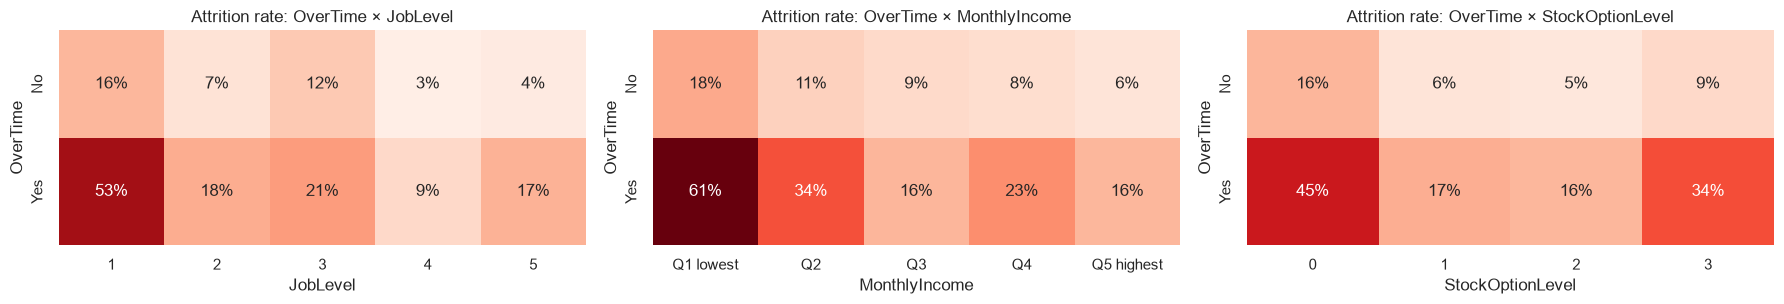

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.2))
for ax, c in zip(axes, [df["JobLevel"], bands["MonthlyIncome"], df["StockOptionLevel"]]):
    sns.heatmap(df.pivot_table(index="OverTime", columns=c, values="Left", observed=True), annot=True, fmt=".0%",
                cmap="Reds", vmin=0, vmax=0.6, cbar=False, ax=ax)
    ax.set_title(f"Attrition rate: OverTime × {c.name}")
fig.tight_layout()

## 5 Groups of similar employees (clustering)
K-Means sorts employees into groups that look alike. We check whether such groups differ in attrition.
The silhouette score says how clearly the groups are separated: near 0 = blurry, near 1 = clear.

In [13]:
X = StandardScaler().fit_transform(df[num_cols])
sil = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in range(2, 7)}
print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()})

silhouette by k: {2: 0.152, 3: 0.132, 4: 0.096, 5: 0.103, 6: 0.078}


In [14]:
K = 2  # best silhouette; k=3 only splits the junior group into two near-identical halves
df["Cluster"] = KMeans(K, n_init=10, random_state=0).fit_predict(X)
profile = df.groupby("Cluster").agg(
    n=("Left", "size"), attrition=("Left", "mean"), age=("Age", "median"), income=("MonthlyIncome", "median"),
    job_level=("JobLevel", "median"), total_years=("TotalWorkingYears", "median"), tenure=("YearsAtCompany", "median"),
    years_in_role=("YearsInCurrentRole", "median"), overtime=("OverTime", lambda s: (s == "Yes").mean()),
).sort_values("attrition", ascending=False)
profile.style.format({"attrition": "{:.1%}", "overtime": "{:.1%}", "income": "{:,.0f}"})

,n,attrition,age,income,job_level,total_years,tenure,years_in_role,overtime
Cluster,,,,,,,,,
1,1001,19.1%,33.000000,"3,894",1.000000,7.000000,4.000000,2.000000,28.9%
0,469,9.8%,42.000000,"10,422",3.000000,18.000000,11.000000,7.000000,27.1%


PC1    TotalWorkingYears, YearsAtCompany, JobLevel, M...
PC2    PerformanceRating, PercentSalaryHike, NumCompa...
Name: strongest features, dtype: str

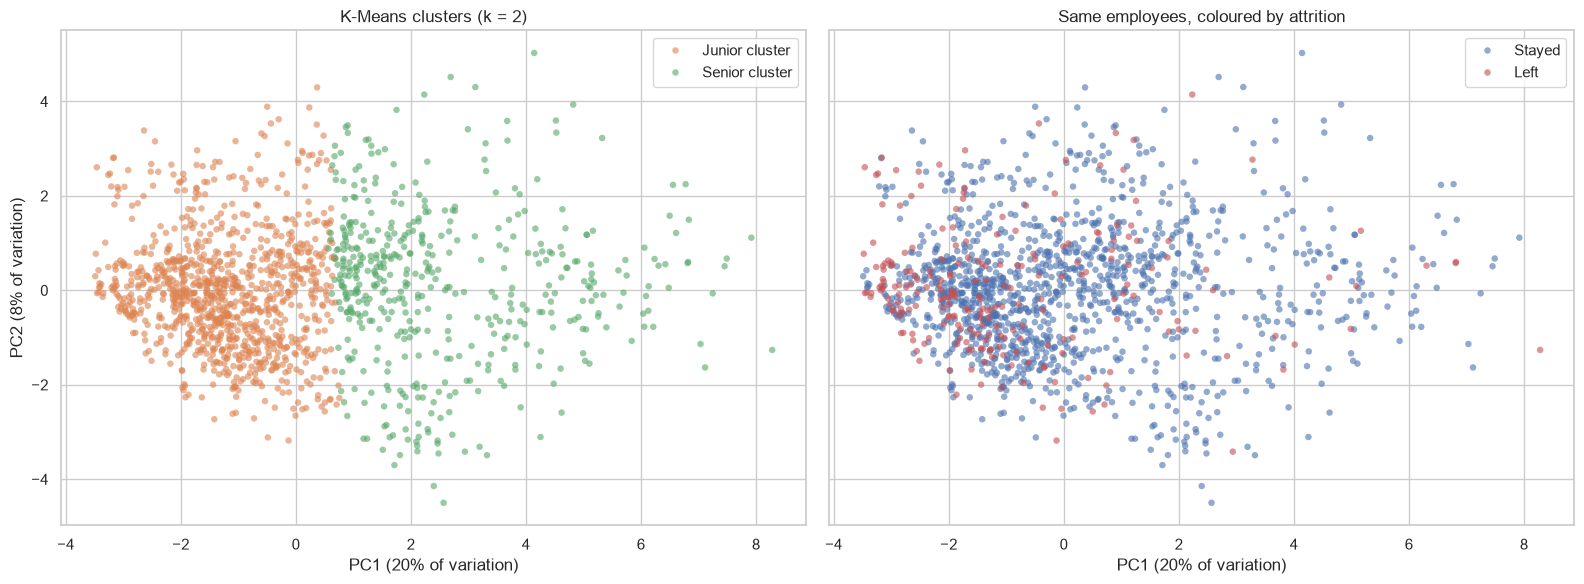

In [ ]:
from sklearn.decomposition import PCA

# 2-D view of the clusters: PCA squeezes the numeric features into the two directions with the most variation
pca = PCA(2, random_state=0).fit(X)
pc = pd.DataFrame(pca.transform(X), columns=["PC1", "PC2"], index=df.index)
senior = df.groupby("Cluster")["MonthlyIncome"].median().idxmax()
pc["Group"] = np.where(df["Cluster"] == senior, "Senior cluster", "Junior cluster")
pc["Outcome"] = df["Left"].map({0: "Stayed", 1: "Left"})

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="Group", hue_order=["Junior cluster", "Senior cluster"],
                palette=["#dd8452", "#55a868"], s=22, alpha=0.6, linewidth=0, ax=axes[0])
axes[0].set_title("K-Means clusters (k = 2)")
sns.scatterplot(data=pc.sort_values("Outcome", ascending=False), x="PC1", y="PC2", hue="Outcome",
                hue_order=["Stayed", "Left"], palette=[BLUE, RED], s=22, alpha=0.6, linewidth=0, ax=axes[1])
axes[1].set_title("Same employees, coloured by attrition")
ev = pca.explained_variance_ratio_
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variation)")
    ax.legend(title="")
fig.tight_layout()
pd.DataFrame(pca.components_.T, index=num_cols, columns=["PC1", "PC2"]).abs().apply(lambda s: ", ".join(s.nlargest(4).index)).rename("strongest features")

- The scores are low (at most 0.15), so there are **no clear-cut employee types**.
- The one stable split is **seniority**: an experienced, well-paid third (about 10 % leave) and a junior two-thirds (about 19 % leave).
- Both groups work overtime equally often (about 28 %), so overtime is a risk on its own, whatever the seniority.
- The simple hand-made groups in section 4 show the differences in attrition much more clearly.

## 6 Outliers
A value counts as an outlier if it lies far outside the middle half of the data (1.5 × IQR rule).

In [15]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
out = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
out[out > 0].sort_values(ascending=False).to_frame("n outliers").assign(share=lambda d: (d["n outliers"] / len(df)).round(3))

,n outliers,share
TrainingTimesLastYear,238,0.162
PerformanceRating,226,0.154
MonthlyIncome,114,0.078
YearsSinceLastPromotion,107,0.073
YearsAtCompany,104,0.071
StockOptionLevel,85,0.058
TotalWorkingYears,63,0.043
NumCompaniesWorked,52,0.035
YearsInCurrentRole,21,0.014
YearsWithCurrManager,14,0.010


- `TrainingTimesLastYear`, `PerformanceRating`, `StockOptionLevel`: not real outliers. These columns just have very few different values.
- `MonthlyIncome` and the tenure columns: a small group of long-serving, well-paid senior staff. Believable values, no errors.
- **Decision: keep all rows.** Tree models cope well with extreme values.

## 7 Takeaways

**Workforce.** 1,470 employees. The typical employee is 36 years old, earns 4,919 a month and has been with the company for 5 years. 65 % work in R&D, 30 % in Sales, 4 % in HR. 28 % work overtime.

**16 % left (237 employees), but not evenly:**

| Group | Share that left | Compared with |
|---|---|---|
| Works overtime | 31 % | 10 % without |
| First 0–1 years at company | 35 % | 8 % after 11+ years |
| Age 18–25 | 36 % | 9 % age 36–45 |
| Lowest income fifth | 31 % | 9 % highest fifth |
| Job level 1 | 26 % | 5–7 % levels 4–5 |
| No stock options | 24 % | 8–9 % levels 1–2 |
| Sales Representative | 40 % | 2–5 % Research Director / Manager |
| Single | 26 % | 10–12 % divorced / married |
| Frequent business travel | 25 % | 8 % non-travel |
| Lowest work-life balance / job involvement | 31 % / 34 % | about 14 % typical |

**Risks add up.** Overtime + job level 1: **53 %** leave (n = 156). Overtime + lowest income fifth: **61 %** (n = 88).

**Makes no difference:** gender, education level, performance rating, daily/hourly/monthly rate.

**Typical leaver:** young, new, entry-level, low pay, works overtime, no stock options. Most common among Sales Representatives and Laboratory Technicians.

**Careful.** These are patterns, not proven causes. Many are linked: older employees also earn more and have stayed longer. Some groups are small (e.g. HR education field, n = 27). The model and XAI step checks which factors still matter once the others are taken into account.

**For the model.**
- Few leavers → keep the 16 % rate in training and test data, and judge the model by how many leavers it finds.
- Effects come from combinations → use a tree model.
- Twin features (seniority/pay, tenure) → read SHAP/LIME importance per group, not per single feature.